Name:
Aarohi Nagdeote
Arya Mahajan
Moksh Barapatre

Subject: MLDS LAB

Section: B3

Roll no.: 01, 03, 49

# MLDS Project: AI-Based Predictive Maintenance

This project uses the AI4I 2020 machine sensor data to study machine failures. It covers data inspection, exploratory data analysis, sampling methods, the Central Limit Theorem, hypothesis tests, and machine learning models.

The target is `Machine failure`. The failure-mode columns `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` are not used as inputs for the overall model because they directly reveal the failure outcome.

## 1. Introduction and Objective

The objective is to understand the sensor readings, practise common sampling methods, use the Central Limit Theorem, test a few clear hypotheses, and then build simple classification models for machine failure.

The notebook follows one continuous practical: inspect the data, explore it, sample it, study sample means, test hypotheses, preprocess the data, train three classifiers, and compare them in one evaluation table.

## 2. Import Libraries

We use pandas and NumPy for data work, Matplotlib and Seaborn for plots, SciPy for statistical tests, and scikit-learn for preprocessing, models, and metrics.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

## 3. Load and Inspect the Dataset

The CSV is in the `data` folder. The small path check lets the notebook run from the project root or from the `notebooks` folder.

In [3]:
data_path = Path("data/ai4i2020.csv")
if not data_path.exists():
    data_path = Path("../data/ai4i2020.csv")

df = pd.read_csv(data_path)

target = "Machine failure"

print("Loaded:", data_path)

Loaded: ..\data\ai4i2020.csv


The first five rows show the table layout and the values stored in each column.

In [4]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


The shape gives the number of records and columns.

In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 10000
Columns: 14


The column names show which fields are available for analysis and modelling.

In [6]:
print(df.columns.tolist())

['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


Data types tell us which columns are numeric and which are text.

In [7]:
df.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Missing values and duplicate rows are data-quality checks.

In [8]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


Descriptive statistics summarise the centre and spread of the numeric columns.

In [10]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


The target counts and percentage show how common machine failure is.

In [11]:
df[target].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [12]:
print("Failure percentage:", round(df[target].mean() * 100, 2), "%")

Failure percentage: 3.39 %


The dataset has 10,000 rows and 14 columns, with no missing values and no duplicate rows. The target is binary and only 339 records (3.39%) are failures, so the classes are imbalanced.

## 4. Exploratory Data Analysis

EDA helps us see the shape of each variable, compare groups, and spot relationships before testing or modelling.

### 4.1 Univariate Analysis

We start with one variable at a time. The count plot shows the class imbalance, and the histograms show the range and shape of each sensor reading.

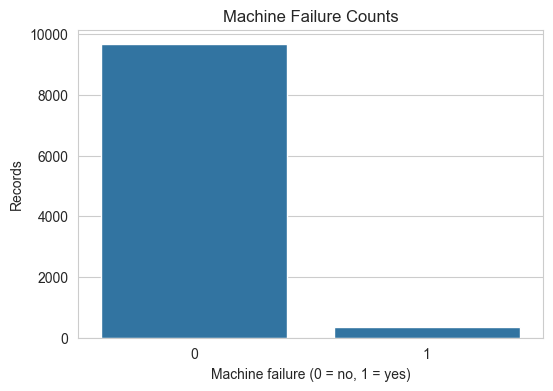

In [13]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target)
plt.title("Machine Failure Counts")
plt.xlabel("Machine failure (0 = no, 1 = yes)")
plt.ylabel("Records")
plt.show()

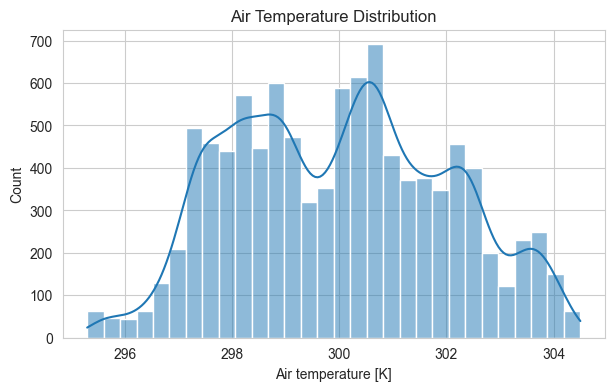

In [14]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Air temperature [K]", bins=30, kde=True)
plt.title("Air Temperature Distribution")
plt.show()

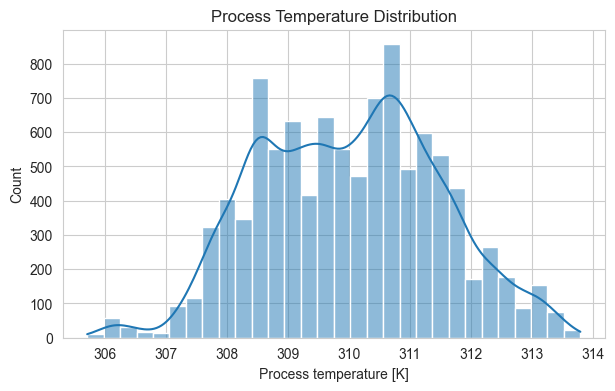

In [15]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Process temperature [K]", bins=30, kde=True)
plt.title("Process Temperature Distribution")
plt.show()

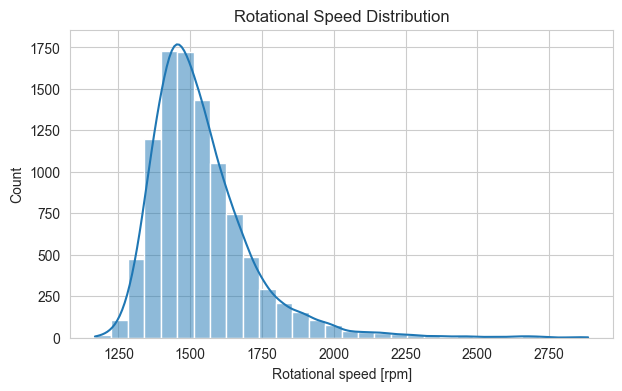

In [16]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Rotational speed [rpm]", bins=30, kde=True)
plt.title("Rotational Speed Distribution")
plt.show()

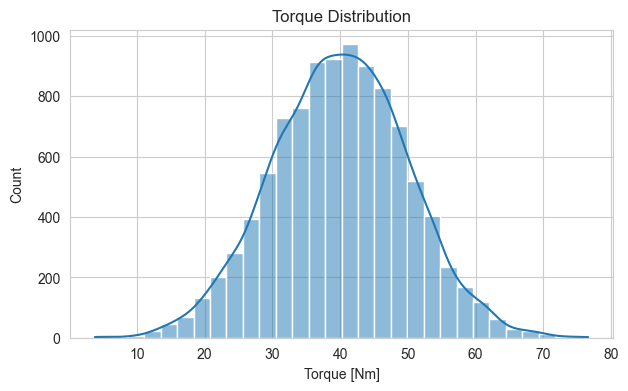

In [17]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Torque [Nm]", bins=30, kde=True)
plt.title("Torque Distribution")
plt.show()

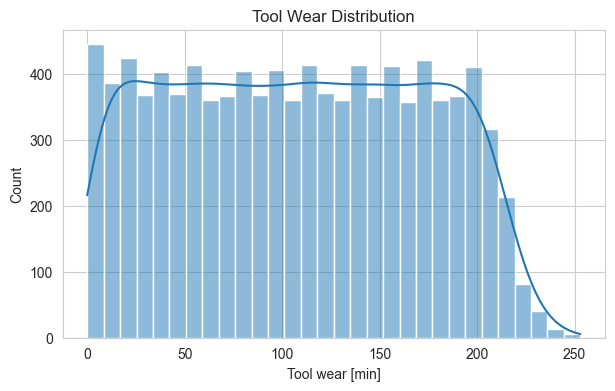

In [18]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Tool wear [min]", bins=30, kde=True)
plt.title("Tool Wear Distribution")
plt.show()

In [19]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

Boxplots make unusual values and the middle 50% of each feature easier to see.

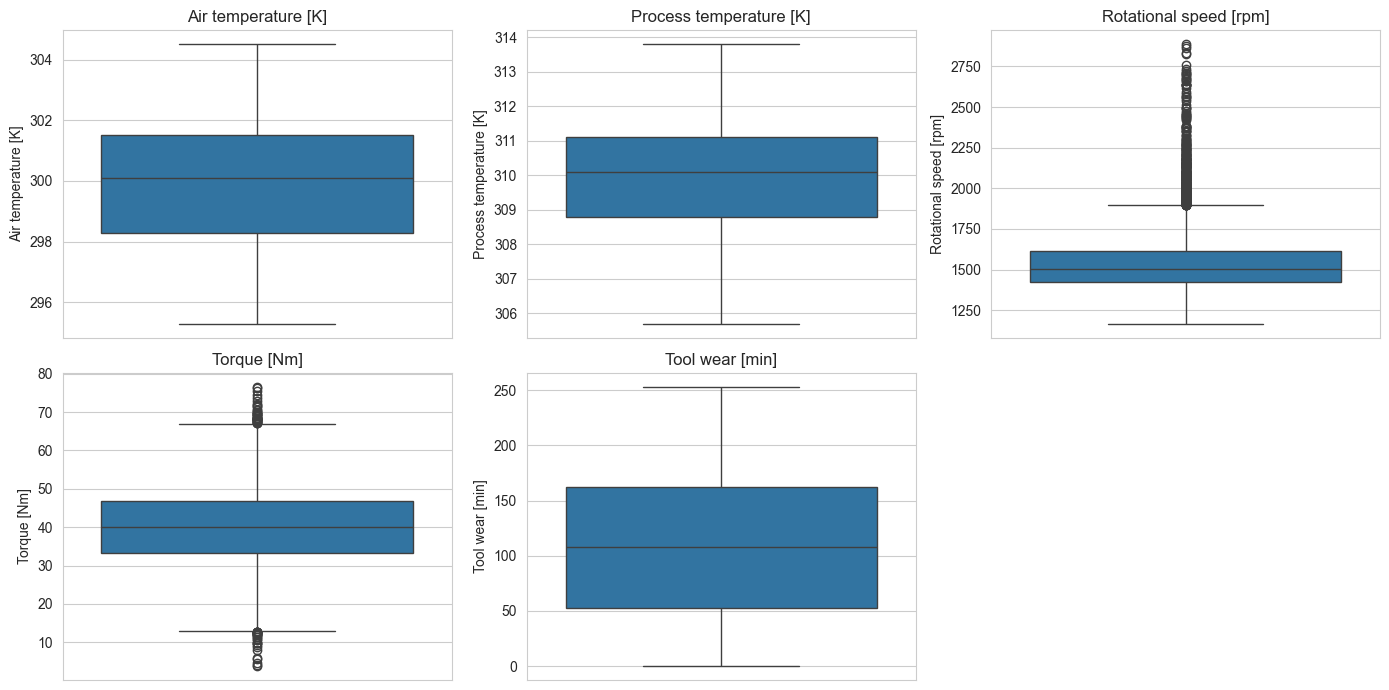

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for ax, column in zip(axes.flat, numeric_features):
    sns.boxplot(data=df, y=column, ax=ax)
    ax.set_title(column)

fig.delaxes(axes.flat[5])
plt.tight_layout()
plt.show()

### 4.2 Categorical Analysis

`Type` is the categorical input. We compare its counts and its failure rates.

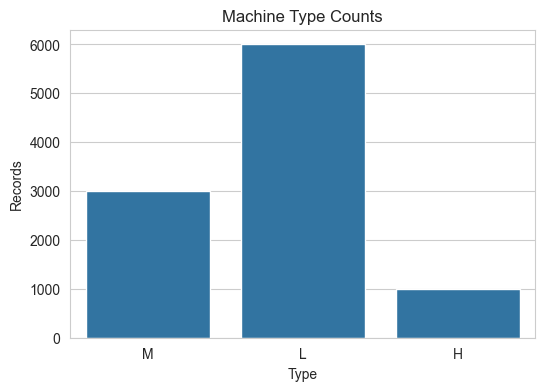

In [21]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Type")
plt.title("Machine Type Counts")
plt.xlabel("Type")
plt.ylabel("Records")
plt.show()

In [22]:
type_failure_table = pd.crosstab(df["Type"], df[target])
type_failure_table

Machine failure,0,1
Type,,
H,982,21
L,5765,235
M,2914,83


In [23]:
type_failure_rate = (
    type_failure_table[1] / type_failure_table.sum(axis=1) * 100
).round(2)
type_failure_rate.name = "Failure %"
type_failure_rate

Type
H    2.09
L    3.92
M    2.77
Name: Failure %, dtype: float64

### 4.3 Bivariate Analysis

We compare the sensor readings between failed and non-failed machines. The count plot shows how failure counts are spread across types.

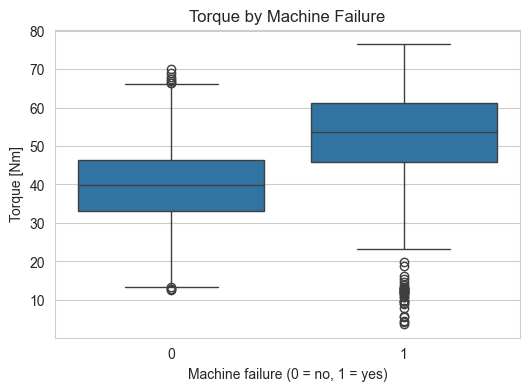

In [24]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x=target, y="Torque [Nm]")
plt.title("Torque by Machine Failure")
plt.xlabel("Machine failure (0 = no, 1 = yes)")
plt.show()

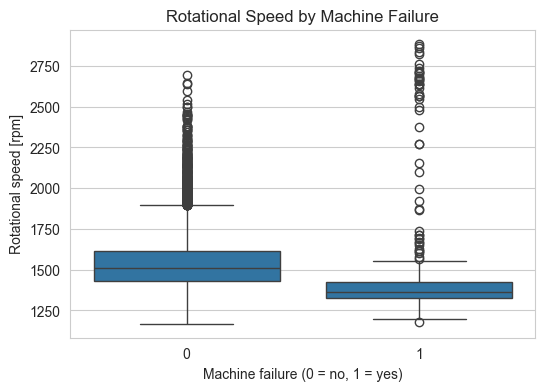

In [25]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x=target, y="Rotational speed [rpm]")
plt.title("Rotational Speed by Machine Failure")
plt.xlabel("Machine failure (0 = no, 1 = yes)")
plt.show()

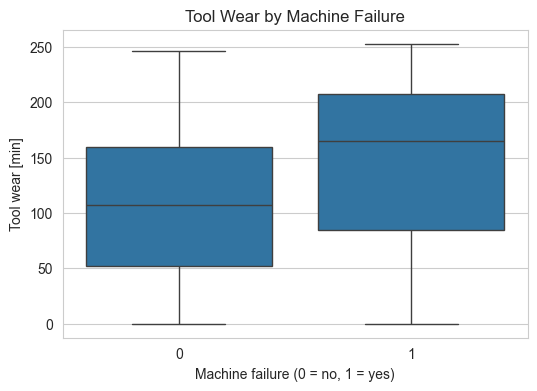

In [26]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x=target, y="Tool wear [min]")
plt.title("Tool Wear by Machine Failure")
plt.xlabel("Machine failure (0 = no, 1 = yes)")
plt.show()

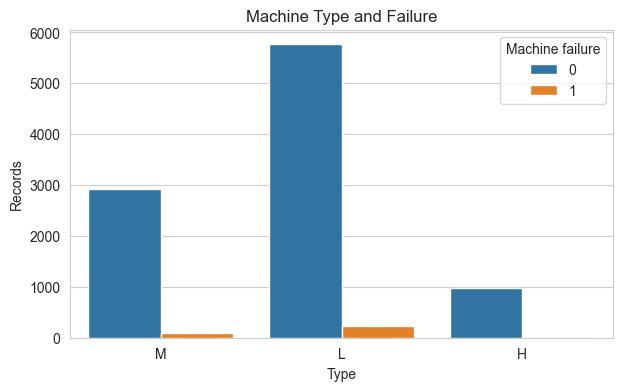

In [27]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Type", hue=target)
plt.title("Machine Type and Failure")
plt.xlabel("Type")
plt.ylabel("Records")
plt.show()

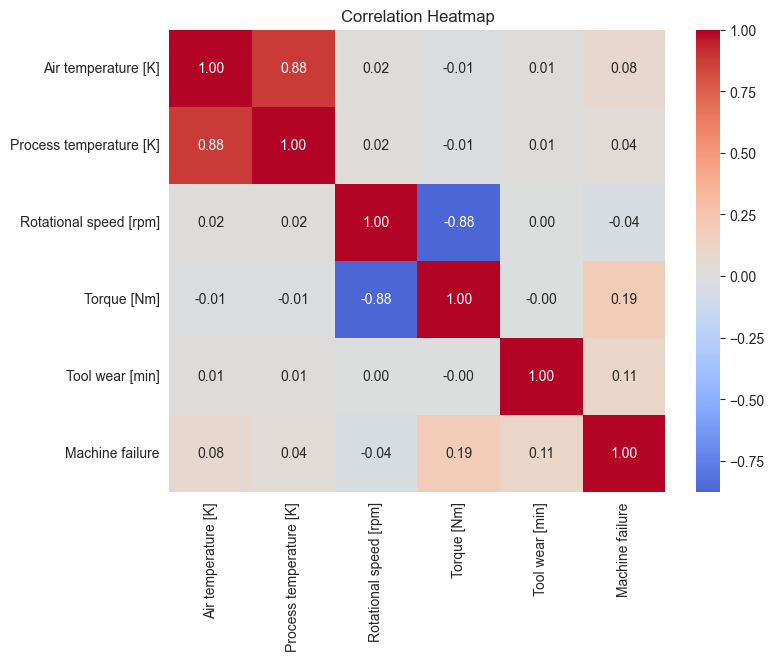

In [28]:
corr_columns = numeric_features + [target]

plt.figure(figsize=(8, 6))
sns.heatmap(
    df[corr_columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Correlation Heatmap")
plt.show()

### 4.4 Grouped Analysis

Group means summarise the average difference between failed and non-failed records.

In [29]:
df.groupby(target)[numeric_features].mean().round(2).T

Machine failure,0,1
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78


### 4.5 EDA Interpretation

The failure rate is 3.39%, so the classes are imbalanced. Failed machines have higher mean torque (50.17 vs 39.63 Nm) and tool wear (143.78 vs 106.69 min), and lower mean rotational speed (1496.49 vs 1540.26 rpm). The boxplots still show overlapping ranges, so no single feature separates the classes perfectly.

Type L has the highest failure percentage (3.92%), followed by M (2.77%) and H (2.09%). The correlation heatmap shows only weak-to-moderate linear relationships with failure, for example 0.19 for torque and 0.11 for tool wear. These patterns are descriptive and do not prove causation.

## 5. Sampling and Sampling Techniques

The population here is the full set of 10,000 records in the dataset we are studying. A sample is a smaller subset selected from those records. Sampling is useful when checking every record is expensive, but a badly selected sample can be biased.

This finite dataset is not the same as every machine in the real world. The demonstrations below show how the methods work; they do not prove that one sample represents all machines.

### 5.1 Simple Random Sampling

Simple random sampling gives every record an equal chance of being selected. We take 100 rows with `df.sample()`.

In [30]:
simple_sample = df.sample(n=100, random_state=42)

In [31]:
print("Shape:", simple_sample.shape)
simple_sample.head()

Shape: (100, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
6252,6253,L53432,L,300.8,310.3,1538,36.1,198,0,0,0,0,0,0
4684,4685,M19544,M,303.6,311.8,1421,44.8,101,1,0,0,0,0,0
1731,1732,M16591,M,298.3,307.9,1485,42.0,117,0,0,0,0,0,0
4742,4743,L51922,L,303.3,311.3,1592,33.7,14,0,0,0,0,0,0
4521,4522,L51701,L,302.4,310.4,1865,23.9,129,0,0,0,0,0,0


### 5.2 Systematic Sampling

We choose a random starting row and then take every kth row. Here k is the population size divided by the desired sample size.

In [32]:
population_size = len(df)
sample_size = 100
k = population_size // sample_size
start = np.random.default_rng(42).integers(0, k)

systematic_sample = df.iloc[start::k].head(sample_size)

In [33]:
print("k:", k)
print("Start:", start)
print("Shape:", systematic_sample.shape)
systematic_sample.head()

k: 100
Start: 8
Shape: (100, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
108,109,H29522,H,298.9,308.8,1621,32.7,75,0,0,0,0,0,0
208,209,L47388,L,298.4,308.6,1591,36.7,122,0,0,0,0,0,0
308,309,L47488,L,297.9,308.5,1305,47.2,155,0,0,0,0,0,0
408,409,M15268,M,297.4,308.6,1434,44.4,193,0,0,0,0,0,0


Systematic sampling is easy to spread across the file, but it can introduce bias if the row order contains a repeating pattern.

### 5.3 Stratified Sampling

Stratified sampling keeps the failure and non-failure proportions as close as the sample size allows. This is useful because failures are rare.

In [34]:
sample_fraction = 100 / len(df)

if df[target].value_counts().min() < 2:
    stratified_sample = df.sample(n=min(100, len(df)), random_state=42)
    print("A stratum was too small; used a simple random sample.")
else:
    stratified_sample, _ = train_test_split(
        df,
        train_size=sample_fraction,
        stratify=df[target],
        random_state=42,
    )

In [35]:
print("Original proportions:")
print(df[target].value_counts(normalize=True).round(4))

print("\nStratified sample proportions:")
print(stratified_sample[target].value_counts(normalize=True).round(4))

Original proportions:
Machine failure
0    0.9661
1    0.0339
Name: proportion, dtype: float64

Stratified sample proportions:
Machine failure
0    0.97
1    0.03
Name: proportion, dtype: float64


In [36]:
print("Shape:", stratified_sample.shape)
stratified_sample.head()

Shape: (100, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
4612,4613,L51792,L,303.0,311.3,2194,16.5,148,0,0,0,0,0,0
1526,1527,L48706,L,298.1,309.0,1787,27.6,47,0,0,0,0,0,0
5497,5498,M20357,M,302.9,312.5,1551,40.0,20,0,0,0,0,0,0
9800,9801,H39214,H,298.5,309.3,1421,50.3,124,0,0,0,0,0,0
6994,6995,L54174,L,300.6,310.8,1375,53.2,179,0,0,0,0,0,0


### 5.4 Cluster Sampling

We randomly choose a machine `Type` group and include all records from that group. This is a simplified cluster sample because `Type` is not necessarily a naturally independent cluster.

In [37]:
clusters = df["Type"].unique()
cluster_rng = np.random.default_rng(42)
chosen_types = cluster_rng.choice(clusters, size=1, replace=False)
cluster_sample = df[df["Type"].isin(chosen_types)]

In [38]:
print("Chosen type:", chosen_types)
print("Shape:", cluster_sample.shape)
cluster_sample.head()

Chosen type: ['M']
Shape: (2997, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0
12,13,M14872,M,298.6,309.1,1339,51.1,34,0,0,0,0,0,0


A cluster sample is cheap when records are already grouped, but one type may not represent the whole dataset. The selected cluster can be much larger than 100 records because every record in that group is included.

### 5.5 Convenience Sampling

We take the first 100 rows because they are easy to access. This is convenience sampling, not a random method.

In [39]:
convenience_sample = df.head(100)
print("Shape:", convenience_sample.shape)
convenience_sample.head()

Shape: (100, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Convenience samples are fast but may be biased if the file is ordered. This method is shown only for comparison and is not recommended for inference.

### 5.6 Sampling Comparison

The failure percentage changes from sample to sample, especially because failures are rare.

In [40]:
sample_summary = pd.DataFrame(
    [
        ["Original dataset", len(df), round(df[target].mean() * 100, 2)],
        ["Simple random", len(simple_sample), round(simple_sample[target].mean() * 100, 2)],
        ["Systematic", len(systematic_sample), round(systematic_sample[target].mean() * 100, 2)],
        ["Stratified", len(stratified_sample), round(stratified_sample[target].mean() * 100, 2)],
        ["Cluster", len(cluster_sample), round(cluster_sample[target].mean() * 100, 2)],
        ["Convenience", len(convenience_sample), round(convenience_sample[target].mean() * 100, 2)],
    ],
    columns=["Technique", "Rows", "Failure %"],
)
sample_summary

,Technique,Rows,Failure %
0,Original dataset,10000,3.39
1,Simple random,100,3.00
2,Systematic,100,2.00
3,Stratified,100,3.00
4,Cluster,2997,2.77
5,Convenience,100,3.00


In [41]:
sampling_table = pd.DataFrame(
    [
        ["Simple random", "Random rows with df.sample()", "Each record has an equal chance", "Rare failures may be missed"],
        ["Systematic", "Every kth row after a random start", "Easy to spread across the file", "Bias if row order has a pattern"],
        ["Stratified", "Sample within each failure group", "Keeps rare failure proportions", "Needs a stratum label"],
        ["Cluster", "Choose Type groups and include all rows", "Cheap for grouped records", "One group may not represent all machines"],
        ["Convenience", "First 100 rows", "Quick and easy", "Likely biased; not recommended"],
    ],
    columns=["Sampling technique", "How records are selected", "Main advantage", "Main limitation"],
)
sampling_table

,Sampling technique,How records are selected,Main advantage,Main limitation
0,Simple random,Random rows with df.sample(),Each record has an equal chance,Rare failures may be missed
1,Systematic,Every kth row after a random start,Easy to spread across the file,Bias if row order has a pattern
2,Stratified,Sample within each failure group,Keeps rare failure proportions,Needs a stratum label
3,Cluster,Choose Type groups and include all rows,Cheap for grouped records,One group may not represent all machines
4,Convenience,First 100 rows,Quick and easy,Likely biased; not recommended


The samples above are subsets of the same dataset, not independent datasets. A single sample can be far from the full-data failure rate, so one sample should not be treated as proof about all machines.

## 6. Central Limit Theorem (CLT)

The Central Limit Theorem says that, under suitable conditions, the distribution of sample means tends toward a normal distribution as the sample size increases, even when the individual values are not normal. We use `Torque [Nm]` for this experiment.

### 6.1 Population Distribution

We treat the 10,000 observed torque values as the finite population for this exercise.

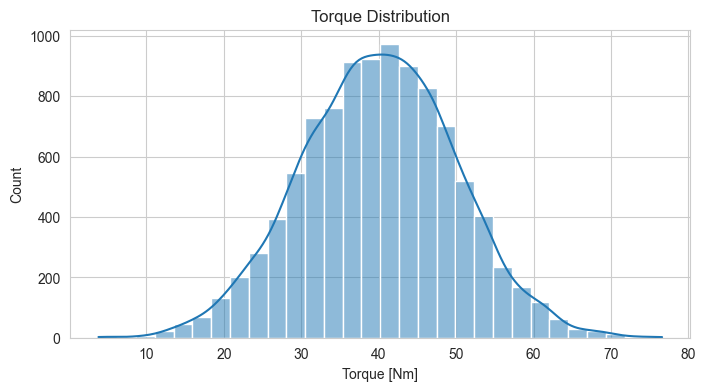

In [42]:
torque = df["Torque [Nm]"]

plt.figure(figsize=(8, 4))
sns.histplot(torque, bins=30, kde=True)
plt.title("Torque Distribution")
plt.xlabel("Torque [Nm]")
plt.show()

In [43]:
torque_mean = torque.mean()
torque_std = torque.std(ddof=0)

print("Mean torque:", round(torque_mean, 3))
print("Population standard deviation (ddof=0):", round(torque_std, 3))

Mean torque: 39.987
Population standard deviation (ddof=0): 9.968


We use `ddof=0` because we treat all 10,000 records as the population. These values are not necessarily the true parameters of every machine in the real world.

### 6.2 Generate Sample Means

We draw 1,000 random samples of size 30 with replacement and record the mean torque of each sample.

In [44]:
rng = np.random.default_rng(42)
sample_means_30 = []

for i in range(1000):
    sample = rng.choice(torque.values, size=30, replace=True)
    sample_means_30.append(sample.mean())

sample_means_30 = pd.Series(sample_means_30)

### 6.3 Visualize the Sampling Distribution

The histogram shows the distribution of the 1,000 sample means. The red curve is a normal curve with the same mean and standard deviation.

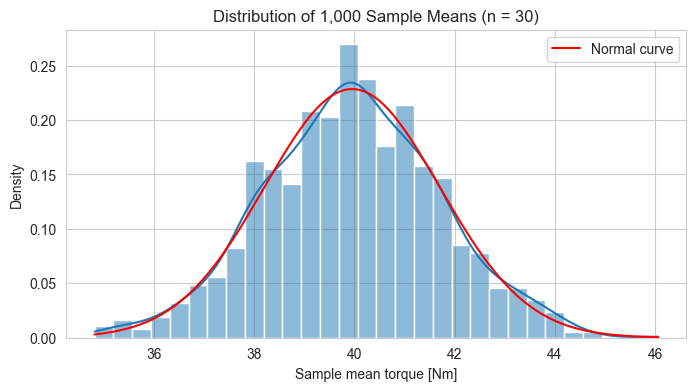

In [45]:
plt.figure(figsize=(8, 4))
sns.histplot(sample_means_30, bins=30, stat="density", kde=True)

x_values = np.linspace(sample_means_30.min(), sample_means_30.max(), 200)
normal_curve = stats.norm.pdf(
    x_values,
    sample_means_30.mean(),
    sample_means_30.std(),
)
plt.plot(x_values, normal_curve, color="red", label="Normal curve")

plt.title("Distribution of 1,000 Sample Means (n = 30)")
plt.xlabel("Sample mean torque [Nm]")
plt.legend()
plt.show()

In [46]:
mean_of_means = sample_means_30.mean()
se_estimated = sample_means_30.std()
se_theoretical = torque_std / np.sqrt(30)

print("Mean of sample means:", round(mean_of_means, 3))
print("SD of sample means (estimated SE):", round(se_estimated, 3))
print("Theoretical SE:", round(se_theoretical, 3))
print("Difference:", round(abs(se_estimated - se_theoretical), 3))

Mean of sample means: 39.957
SD of sample means (estimated SE): 1.746
Theoretical SE: 1.82
Difference: 0.074


The mean of the sample means should be close to the population mean. The standard deviation of the 1,000 means (using pandas' default `ddof=1`) estimates the standard error, and it should be close to the theoretical value `sigma / sqrt(n)`.

### 6.4 Compare Different Sample Sizes

We reuse the 1,000 sample means for size 30 from above and generate the same number of samples for sizes 5 and 100. All use the same population.

In [47]:
rng = np.random.default_rng(42)
means_by_size = {30: sample_means_30}

for n_size in [5, 100]:
    sample_means = []
    for i in range(1000):
        sample = rng.choice(torque.values, size=n_size, replace=True)
        sample_means.append(sample.mean())
    means_by_size[n_size] = pd.Series(sample_means)

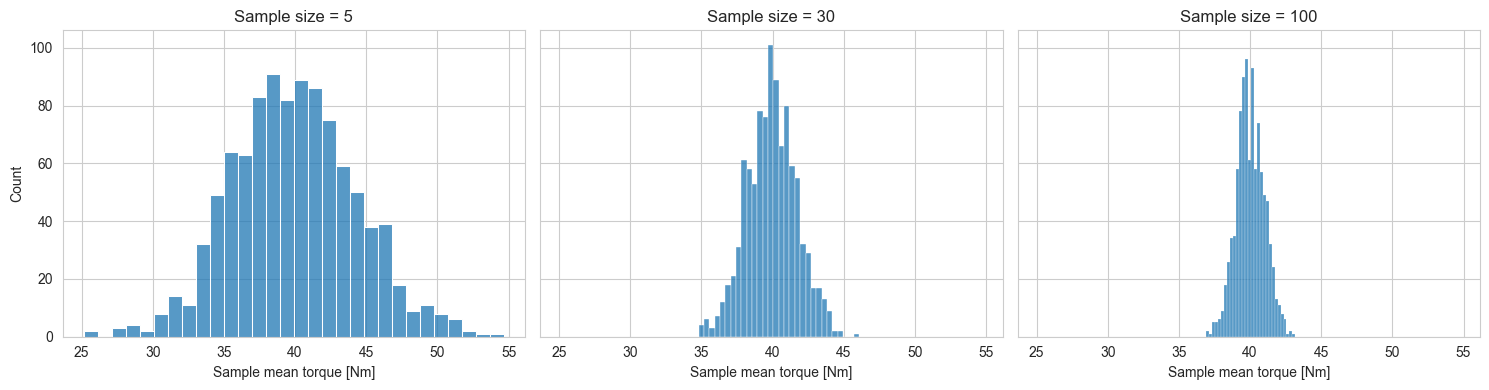

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

for ax, n_size in zip(axes, [5, 30, 100]):
    sns.histplot(means_by_size[n_size], bins=30, ax=ax)
    ax.set_title("Sample size = " + str(n_size))
    ax.set_xlabel("Sample mean torque [Nm]")

plt.tight_layout()
plt.show()

In [49]:
clt_rows = []

for n_size in [5, 30, 100]:
    clt_rows.append(
        [
            n_size,
            round(means_by_size[n_size].mean(), 3),
            round(means_by_size[n_size].std(), 3),
            round(torque_std / np.sqrt(n_size), 3),
        ]
    )

clt_summary = pd.DataFrame(
    clt_rows,
    columns=["Sample size", "Mean of means", "SD of means", "Theoretical SE"],
)
clt_summary

,Sample size,Mean of means,SD of means,Theoretical SE
0,5,39.919,4.394,4.458
1,30,39.957,1.746,1.820
2,100,39.997,0.994,0.997


The distributions become more concentrated as the sample size increases. The standard deviation of the sample means falls as `n` grows, which is why the theoretical standard error uses `sqrt(n)` in the denominator. A larger sample does not fix a biased sampling method; it only reduces the variability of the sample mean.

### 6.5 CLT Conclusion

The sample means stay centred near the observed population mean of about 39.99 Nm. For sample size 30, the standard deviation of the 1,000 means is close to the theoretical standard error, and the histogram is roughly bell-shaped. The sample size 5 distribution is wider, while the sample size 100 distribution is narrower. The CLT describes the behaviour of sample means, not individual torque values, and it does not guarantee perfect normality or remove sampling bias. The repeated samples are resamples of the same finite dataset, not new independent observations from the real world.

## 7. Hypothesis Testing Introduction

A null hypothesis (`H0`) usually states that there is no difference or no association. The alternative hypothesis (`H1`) states the change we are looking for. The significance level `alpha` is the maximum false-positive risk we allow, and we use 0.05 here.

The test statistic measures how far the observed result is from what `H0` predicts. The p-value is the probability of getting a result at least as extreme as the observed one if `H0` is true. If the p-value is less than 0.05, we reject `H0`; otherwise we fail to reject it. Failing to reject `H0` does not prove that `H0` is true. All tests below are two-sided unless stated otherwise.

In [50]:
alpha = 0.05

## 8. Z-Test for the Failure Proportion

The target is binary, so a one-proportion z-test is appropriate for a hypothesis about its proportion. We compare the observed failure proportion with a hypothetical benchmark of 5%. This 5% value is only a reference for the exercise, not an established industry failure rate. The test treats the 10,000 records as independent observations from a common process; this is an assumption, not a proven fact about the dataset.

- `H0`: the population failure proportion is 0.05.
- `H1`: the population failure proportion is not 0.05.

In [51]:
p0 = 0.05

In [52]:
failures = int(df[target].sum())
total_records = len(df)
p_hat = failures / total_records

print("Failures:", failures)
print("Sample size:", total_records)
print("Observed proportion:", round(p_hat, 4))

Failures: 339
Sample size: 10000
Observed proportion: 0.0339


The normal approximation is reasonable when the expected number of successes and failures under `H0` are both large enough.

In [53]:
expected_failures = total_records * p0
expected_non_failures = total_records * (1 - p0)

print("Expected failures under H0:", expected_failures)
print("Expected non-failures under H0:", expected_non_failures)

Expected failures under H0: 500.0
Expected non-failures under H0: 9500.0


In [54]:
standard_error = np.sqrt(p0 * (1 - p0) / total_records)
z_stat = (p_hat - p0) / standard_error
p_value_z = 2 * stats.norm.sf(abs(z_stat))

print("Z-statistic:", round(z_stat, 4))
print("P-value:", p_value_z)

Z-statistic: -7.3872
P-value: 1.49968034759217e-13


In [55]:
proportion_se = np.sqrt(p_hat * (1 - p_hat) / total_records)
ci_low = p_hat - 1.96 * proportion_se
ci_high = p_hat + 1.96 * proportion_se

print("95% CI for failure proportion:", round(ci_low * 100, 2), "% to", round(ci_high * 100, 2), "%")

95% CI for failure proportion: 3.04 % to 3.74 %


In [56]:
if p_value_z < alpha:
    z_decision = "Reject H0"
    z_interpretation = f"Failure rate {p_hat*100:.2f}% is different from the 5% benchmark."
else:
    z_decision = "Fail to reject H0"
    z_interpretation = "No significant evidence that the failure rate differs from 5%."

print(z_decision)

Reject H0


The expected counts are 500 failures and 9,500 non-failures, so the normal approximation is reasonable. The observed failure rate is 3.39%, the z-statistic is -7.39 and the p-value is about 1.5e-13. The approximate 95% confidence interval is about 3.04% to 3.74%, which does not include 5%. We reject `H0` at alpha = 0.05. The failure rate is statistically different from the hypothetical 5% benchmark, but the difference is only 1.61 percentage points, so statistical significance does not automatically mean a large practical difference.

## 9. T-Tests

We use three t-tests for different data layouts: one sample, paired observations, and two independent groups. Each test has the same null-hypothesis logic but a different formula for the standard error.

### 9.1 One-Sample T-Test

We compare the mean torque with a hypothetical reference value of 40 Nm. This is only a round benchmark for the exercise, not a manufacturer's specification.

- `H0`: the population mean torque is 40 Nm.
- `H1`: the population mean torque is not 40 Nm.

In [57]:
reference_torque = 40
one_sample_t, p_value_one_sample = stats.ttest_1samp(
    torque,
    reference_torque,
)

print("Sample mean torque:", round(torque.mean(), 4))
print("T-statistic:", round(one_sample_t, 4))
print("P-value:", p_value_one_sample)

Sample mean torque: 39.9869
T-statistic: -0.1313
P-value: 0.8955343647163926


In [58]:
torque_se = torque.std() / np.sqrt(len(torque))
torque_ci_low = torque.mean() - 1.96 * torque_se
torque_ci_high = torque.mean() + 1.96 * torque_se

print("95% CI for mean torque:", round(torque_ci_low, 2), "to", round(torque_ci_high, 2), "Nm")

95% CI for mean torque: 39.79 to 40.18 Nm


In [59]:
if p_value_one_sample < alpha:
    one_sample_decision = "Reject H0"
    one_sample_interpretation = f"Mean torque {torque.mean():.2f} Nm differs from 40 Nm."
else:
    one_sample_decision = "Fail to reject H0"
    one_sample_interpretation = f"Mean torque {torque.mean():.2f} Nm is not significantly different from 40 Nm."

print(one_sample_decision)

Fail to reject H0


The mean torque is 39.99 Nm, very close to 40 Nm. The t-statistic is -0.13 and the p-value is 0.8955, so we fail to reject `H0`. The 95% confidence interval includes 40 Nm. The result does not prove that the true mean is exactly 40 Nm; it only says the data are consistent with that benchmark. The observations are treated as independent, and the large sample makes the test fairly robust to mild non-normality.

### 9.2 Paired T-Test

The dataset has no before/after measurements or machine IDs, so a treatment-style paired test is not possible. The natural pairing is the two temperature readings taken on the same record: air temperature and process temperature. Both are measured in Kelvin.

- `H0`: the population mean difference between process and air temperature is zero.
- `H1`: the population mean difference is not zero.

In [60]:
air_temperature = df["Air temperature [K]"]
process_temperature = df["Process temperature [K]"]
temperature_difference = process_temperature - air_temperature

print("Mean air temperature:", round(air_temperature.mean(), 3))
print("Mean process temperature:", round(process_temperature.mean(), 3))
print("Mean difference:", round(temperature_difference.mean(), 3))
print("SD of differences:", round(temperature_difference.std(), 3))

Mean air temperature: 300.005
Mean process temperature: 310.006
Mean difference: 10.001
SD of differences: 1.001


In [61]:
paired_t, p_value_paired = stats.ttest_rel(
    process_temperature,
    air_temperature,
)

print("T-statistic:", round(paired_t, 2))
print("P-value:", p_value_paired)

if p_value_paired == 0:
    print("The p-value is below the floating-point display limit, not exactly zero.")

T-statistic: 998.97
P-value: 0.0
The p-value is below the floating-point display limit, not exactly zero.


In [62]:
if p_value_paired < alpha:
    paired_decision = "Reject H0"
    paired_interpretation = f"Process temperature is higher by {temperature_difference.mean():.2f} K on average."
else:
    paired_decision = "Fail to reject H0"
    paired_interpretation = "No significant mean difference between the two temperature readings."

print(paired_decision)

Reject H0


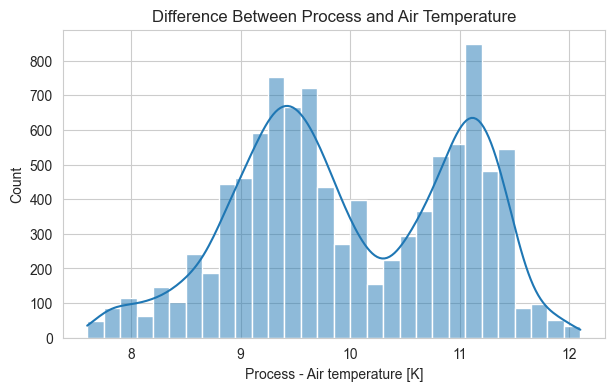

In [63]:
plt.figure(figsize=(7, 4))
sns.histplot(temperature_difference, bins=30, kde=True)
plt.title("Difference Between Process and Air Temperature")
plt.xlabel("Process - Air temperature [K]")
plt.show()

Process temperature is about 10.00 K higher than air temperature on average, with a t-statistic of about 998.97. The p-value is reported as 0.0 because it is far below the display limit, so we reject `H0`. This is a paired comparison of two sensors on the same record, not a before/after treatment effect. The test assumes the differences are independent and approximately normal; the histogram is used as a simple check.

### 9.3 Independent Two-Sample T-Test

We compare mean torque for machines without failure and machines with failure. This is an independent-groups test because each record belongs to only one group. We use the equal-variance version (`equal_var=True`), as requested.

- `H0`: the two population mean torques are equal.
- `H1`: the two population mean torques differ.

In [64]:
no_failure_torque = df[df[target] == 0]["Torque [Nm]"]
failure_torque = df[df[target] == 1]["Torque [Nm]"]

In [65]:
print("No failure:", len(no_failure_torque), "records")
print("Failure:", len(failure_torque), "records")
print("No-failure mean:", round(no_failure_torque.mean(), 3))
print("Failure mean:", round(failure_torque.mean(), 3))
print("No-failure SD:", round(no_failure_torque.std(), 3))
print("Failure SD:", round(failure_torque.std(), 3))

No failure: 9661 records
Failure: 339 records
No-failure mean: 39.63
Failure mean: 50.168
No-failure SD: 9.472
Failure SD: 16.374


In [66]:
independent_t, p_value_independent = stats.ttest_ind(
    no_failure_torque,
    failure_torque,
    equal_var=True,
)

print("T-statistic:", round(independent_t, 4))
print("P-value:", p_value_independent)

T-statistic: -19.4902
P-value: 4.573804886190367e-83


In [67]:
if p_value_independent < alpha:
    independent_decision = "Reject H0"
    independent_interpretation = f"Mean torque differs: {no_failure_torque.mean():.2f} vs {failure_torque.mean():.2f} Nm."
else:
    independent_decision = "Fail to reject H0"
    independent_interpretation = "No significant difference in mean torque."

print(independent_decision)

Reject H0


The equal-variance t-test assumes that both groups have the same population variance. We check this assumption with Levene's test before interpreting the result.

In [68]:
levene_stat, p_value_levene = stats.levene(
    no_failure_torque,
    failure_torque,
)

print("Levene statistic:", round(levene_stat, 4))
print("Levene p-value:", p_value_levene)

Levene statistic: 149.1604
Levene p-value: 4.622859187073166e-34


Levene's test gives p ≈ 4.6e-34, so the equal-variance assumption is not supported: the failure group has a larger torque standard deviation. The equal-variance t-test is reported because it was requested, but its p-value should be interpreted with caution. A test that allows unequal variances would be safer, but it is not included here.

The no-failure group has mean torque 39.63 Nm and the failure group has 50.17 Nm. The t-statistic is -19.49 and the p-value is about 4.6e-83, so we reject `H0`. The observed difference is statistically significant. This is an observational difference, not proof that high torque causes failure.

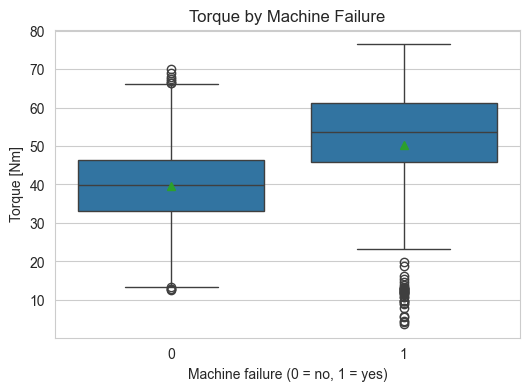

In [69]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x=target, y="Torque [Nm]", showmeans=True)
plt.title("Torque by Machine Failure")
plt.xlabel("Machine failure (0 = no, 1 = yes)")
plt.ylabel("Torque [Nm]")
plt.show()

## 10. Chi-Square Tests

Chi-square tests work with categorical counts. A goodness-of-fit test compares one variable's observed counts with expected proportions. A test of independence checks whether two categorical variables are associated.

### 10.1 Chi-Square Goodness-of-Fit

We check whether the three machine types are equally common in the dataset.

- `H0`: the proportions of L, M, and H are equal (1/3 each).
- `H1`: at least one type proportion differs.

In [70]:
type_counts = type_failure_table.sum(axis=1)
expected_equal = [len(df) / len(type_counts)] * len(type_counts)

type_gof_table = pd.DataFrame(
    {
        "Observed": type_counts,
        "Expected": expected_equal,
    },
    index=type_counts.index,
)
type_gof_table

,Observed,Expected
Type,,
H,1003,3333.333333
L,6000,3333.333333
M,2997,3333.333333


In [71]:
gof_chi2, p_value_gof = stats.chisquare(
    f_obs=type_counts,
    f_exp=expected_equal,
)

print("Chi-square statistic:", round(gof_chi2, 2))
print("Degrees of freedom:", len(type_counts) - 1)
print("P-value:", p_value_gof)

if p_value_gof == 0:
    print("The p-value is below the floating-point display limit, not exactly zero.")

Chi-square statistic: 3796.41
Degrees of freedom: 2
P-value: 0.0
The p-value is below the floating-point display limit, not exactly zero.


The expected count for each type is 3,333.33, and all expected counts are above 5, so the chi-square approximation is reasonable.

In [72]:
if p_value_gof < alpha:
    gof_decision = "Reject H0"
    gof_interpretation = "Machine types are not equally distributed."
else:
    gof_decision = "Fail to reject H0"
    gof_interpretation = "The type proportions are consistent with equal proportions."

print(gof_decision)

Reject H0


The observed counts are L = 6,000, M = 2,997, and H = 1,003. The chi-square statistic is about 3,796.4 with 2 degrees of freedom, and the p-value is below the display limit. We reject `H0`: the dataset does not contain equal numbers of the three types. This describes the composition of the dataset, not the failure rate.

### 10.2 Chi-Square Test of Independence

We check whether machine type and machine-failure status are associated.

- `H0`: machine type and machine-failure status are independent.
- `H1`: machine type and machine-failure status are associated.

The contingency table was created in the categorical EDA section. We reuse it here.

In [73]:
type_failure_table

Machine failure,0,1
Type,,
H,982,21
L,5765,235
M,2914,83


In [74]:
chi2_stat, p_value_chi, dof, expected = stats.chi2_contingency(
    type_failure_table
)

print("Chi-square statistic:", round(chi2_stat, 4))
print("Degrees of freedom:", dof)
print("P-value:", p_value_chi)

Chi-square statistic: 13.7517
Degrees of freedom: 2
P-value: 0.0010324110359454081


In [75]:
expected_table = pd.DataFrame(
    expected,
    index=type_failure_table.index,
    columns=type_failure_table.columns,
)
expected_table.round(2)

Machine failure,0,1
Type,,
H,969.0,34.0
L,5796.6,203.4
M,2895.4,101.6


In [76]:
print("Smallest expected count:", round(expected.min(), 2))

if expected.min() >= 5:
    print("All expected counts are at least 5, so the chi-square approximation is reasonable.")
else:
    print("Some expected counts are below 5; the chi-square approximation may be unreliable.")

Smallest expected count: 34.0
All expected counts are at least 5, so the chi-square approximation is reasonable.


In [77]:
if p_value_chi < alpha:
    chi_decision = "Reject H0"
    chi_interpretation = "Machine type and failure status are associated."
else:
    chi_decision = "Fail to reject H0"
    chi_interpretation = "No significant association was found between type and failure."

print(chi_decision)

Reject H0


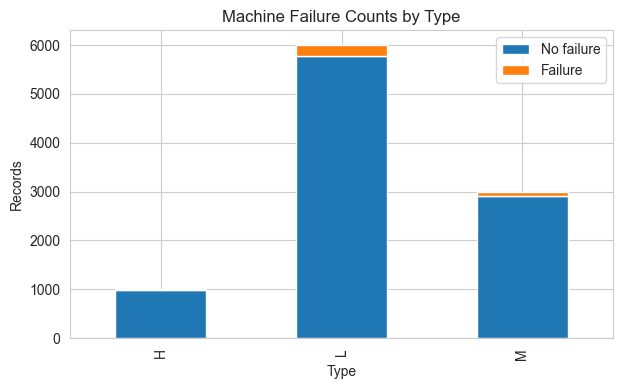

In [78]:
type_failure_table.plot(kind="bar", stacked=True, figsize=(7, 4))
plt.title("Machine Failure Counts by Type")
plt.xlabel("Type")
plt.ylabel("Records")
plt.legend(["No failure", "Failure"])
plt.show()

The chi-square statistic is 13.75 with 2 degrees of freedom and p = 0.00103. The smallest expected count is 34.00, so the approximation is acceptable. We reject `H0`: machine type and failure status are associated in this dataset. Type L has the highest failure percentage (3.92%) and H the lowest (2.09%), but the rates differ by only about 1.8 percentage points, so the practical effect is modest. Association does not establish causation.

## 11. One-Way ANOVA for Torque by Type

One-way ANOVA compares the mean torque across the three machine types L, M, and H. This is preferable to repeating the two-group t-test for the binary failure groups.

- `H0`: all three population mean torques are equal.
- `H1`: at least one population mean torque differs.

In [79]:
torque_L = df[df["Type"] == "L"]["Torque [Nm]"]
torque_M = df[df["Type"] == "M"]["Torque [Nm]"]
torque_H = df[df["Type"] == "H"]["Torque [Nm]"]

In [80]:
for name, group in [("L", torque_L), ("M", torque_M), ("H", torque_H)]:
    print(name, "n =", len(group), "mean =", round(group.mean(), 3))

L n = 6000 mean = 39.997
M n = 2997 mean = 40.017
H n = 1003 mean = 39.838


In [81]:
f_stat, p_value_anova = stats.f_oneway(torque_L, torque_M, torque_H)

print("F-statistic:", round(f_stat, 4))
print("P-value:", p_value_anova)

F-statistic: 0.1282
P-value: 0.8797120606699937


In [82]:
if p_value_anova < alpha:
    anova_decision = "Reject H0"
    anova_interpretation = "At least one machine type has a different mean torque."
else:
    anova_decision = "Fail to reject H0"
    anova_interpretation = "No significant difference among the mean torques of L, M, and H."

print(anova_decision)

Fail to reject H0


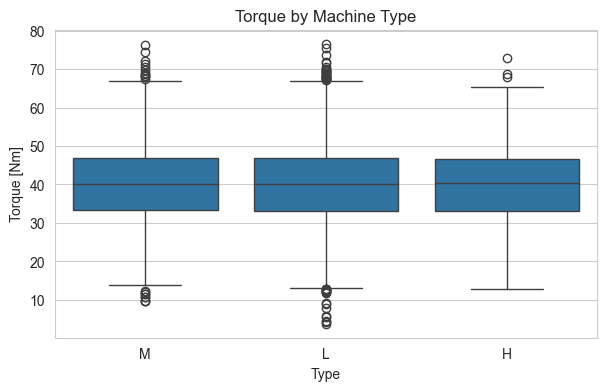

In [83]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Type", y="Torque [Nm]")
plt.title("Torque by Machine Type")
plt.xlabel("Type")
plt.ylabel("Torque [Nm]")
plt.show()

We check the equal-variance assumption with Levene's test and look at group skewness as a simple normality check. The observations are treated as independent records because the dataset does not identify individual machines.

In [84]:
anova_levene_stat, p_value_anova_levene = stats.levene(
    torque_L,
    torque_M,
    torque_H,
)

print("Levene statistic:", round(anova_levene_stat, 4))
print("Levene p-value:", p_value_anova_levene)

Levene statistic: 0.7434
Levene p-value: 0.4755346318239704


In [85]:
df.groupby("Type")["Torque [Nm]"].skew().round(3)

Type
H   -0.085
L   -0.003
M   -0.001
Name: Torque [Nm], dtype: float64

Levene's test gives p = 0.4755, so the equal-variance assumption is reasonable. The group skewness values are close to zero, so approximate normality is acceptable. With large groups, ANOVA is also fairly robust to mild departures from normality.

The F-statistic is 0.128 and the p-value is 0.8797, so we fail to reject `H0`. There is no evidence of a difference in mean torque among the three machine types. ANOVA would not identify which specific groups differ, but here no post-hoc comparison is needed. Failing to reject `H0` does not prove that all three means are exactly equal.

## 12. Summary of Hypothesis Tests

The table combines all seven tests. All decisions use alpha = 0.05.

In [86]:
paired_p_text = f"{p_value_paired:.3e}" if p_value_paired > 0 else "< 1e-300"
gof_p_text = f"{p_value_gof:.3e}" if p_value_gof > 0 else "< 1e-300"

summary_rows = [
    [
        "One-proportion z-test",
        "Machine failure",
        "p = 0.05",
        f"{z_stat:.3f}",
        f"{p_value_z:.3e}",
        z_decision,
        z_interpretation,
    ],
    [
        "One-sample t-test",
        "Torque",
        "Mean torque = 40 Nm",
        f"{one_sample_t:.3f}",
        f"{p_value_one_sample:.3e}",
        one_sample_decision,
        one_sample_interpretation,
    ],
    [
        "Paired t-test",
        "Process vs air temperature",
        "Mean difference = 0",
        f"{paired_t:.3f}",
        paired_p_text,
        paired_decision,
        paired_interpretation,
    ],
    [
        "Independent t-test",
        "Torque by failure",
        "Mean torques equal",
        f"{independent_t:.3f}",
        f"{p_value_independent:.3e}",
        independent_decision,
        independent_interpretation,
    ],
    [
        "Chi-square goodness-of-fit",
        "Type counts",
        "Equal type proportions",
        f"{gof_chi2:.3f}",
        gof_p_text,
        gof_decision,
        gof_interpretation,
    ],
    [
        "Chi-square independence",
        "Type vs failure",
        "Type and failure independent",
        f"{chi2_stat:.3f}",
        f"{p_value_chi:.3e}",
        chi_decision,
        chi_interpretation,
    ],
    [
        "One-way ANOVA",
        "Torque by Type",
        "All type mean torques equal",
        f"{f_stat:.3f}",
        f"{p_value_anova:.3e}",
        anova_decision,
        anova_interpretation,
    ],
]

hypothesis_summary = pd.DataFrame(
    summary_rows,
    columns=[
        "Test",
        "Variables",
        "H0 (short)",
        "Statistic",
        "P-value",
        "Decision",
        "Interpretation",
    ],
)
hypothesis_summary

,Test,Variables,H0 (short),Statistic,P-value,Decision,Interpretation
0,One-proportion z-test,Machine failure,p = 0.05,-7.387,1.500e-13,Reject H0,Failure rate 3.39% is different from the 5% be...
1,One-sample t-test,Torque,Mean torque = 40 Nm,-0.131,8.955e-01,Fail to reject H0,Mean torque 39.99 Nm is not significantly diff...
2,Paired t-test,Process vs air temperature,Mean difference = 0,998.970,< 1e-300,Reject H0,Process temperature is higher by 10.00 K on av...
3,Independent t-test,Torque by failure,Mean torques equal,-19.490,4.574e-83,Reject H0,Mean torque differs: 39.63 vs 50.17 Nm.
4,Chi-square goodness-of-fit,Type counts,Equal type proportions,3796.405,< 1e-300,Reject H0,Machine types are not equally distributed.
5,Chi-square independence,Type vs failure,Type and failure independent,13.752,1.032e-03,Reject H0,Machine type and failure status are associated.
6,One-way ANOVA,Torque by Type,All type mean torques equal,0.128,8.797e-01,Fail to reject H0,No significant difference among the mean torqu...


Seven tests were performed. The p-values are unadjusted, and running several exploratory tests increases the chance of at least one false positive. These results are evidence within this dataset, not proof of causal effects. The independent t-test also has an unequal-variance caveat, and the paired test is a sensor comparison rather than a treatment comparison.

## 13. Data Preprocessing for Machine Learning

The model uses `Type` and the five sensor readings. The failure-mode columns are excluded because they reveal the failure outcome. One-hot encoding converts `Type` into numeric columns, and standard scaling puts the numeric features on a similar scale. The preprocessing is fitted on the training data only, so information from the test set does not leak into training.

In [87]:
categorical_features = ["Type"]
features = categorical_features + numeric_features

X = df[features]
y = df[target]

print("Features:", features)
print("X shape:", X.shape)
print("y shape:", y.shape)

Features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
X shape: (10000, 6)
y shape: (10000,)


In [88]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train failure rate:", round(y_train.mean() * 100, 2), "%")
print("Test failure rate:", round(y_test.mean() * 100, 2), "%")

Train shape: (8000, 6)
Test shape: (2000, 6)
Train failure rate: 3.39 %
Test failure rate: 3.4 %


In [89]:
preprocessor = ColumnTransformer(
    [
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ],
    verbose_feature_names_out=False,
)

In [90]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed train shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)
print("Feature names:", preprocessor.get_feature_names_out())

Processed train shape: (8000, 8)
Processed test shape: (2000, 8)
Feature names: ['Air temperature [K]' 'Process temperature [K]' 'Rotational speed [rpm]'
 'Torque [Nm]' 'Tool wear [min]' 'Type_H' 'Type_L' 'Type_M']


## 14. Machine Learning Models

We train three simple classifiers. Class weights are used because failures are rare, so the models pay more attention to the minority class.

In [91]:
log_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42,
)
log_model.fit(X_train_processed, y_train)
log_pred = log_model.predict(X_test_processed)

In [92]:
tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    min_samples_leaf=5,
    random_state=42,
)
tree_model.fit(X_train_processed, y_train)
tree_pred = tree_model.predict(X_test_processed)

In [93]:
rf_model = RandomForestClassifier(
    n_estimators=160,
    class_weight="balanced_subsample",
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42,
)
rf_model.fit(X_train_processed, y_train)
rf_pred = rf_model.predict(X_test_processed)

In [94]:
models = {
    "Logistic Regression": (log_model, log_pred),
    "Decision Tree": (tree_model, tree_pred),
    "Random Forest": (rf_model, rf_pred),
}

## 15. Model Evaluation

Accuracy is the share of all predictions that are correct. Precision is the share of predicted failures that are real failures. Recall is the share of real failures that the model catches. F1 balances precision and recall. ROC-AUC measures how well the model ranks failure risk, where 0.5 is close to random and 1.0 is perfect. Because failures are rare, accuracy alone can be misleading.

In [95]:
metric_rows = []

for name, (model, pred) in models.items():
    probability = model.predict_proba(X_test_processed)[:, 1]
    metric_rows.append(
        [
            name,
            accuracy_score(y_test, pred),
            precision_score(y_test, pred, zero_division=0),
            recall_score(y_test, pred, zero_division=0),
            f1_score(y_test, pred, zero_division=0),
            roc_auc_score(y_test, probability),
        ]
    )

evaluation_table = pd.DataFrame(
    metric_rows,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
).set_index("Model")

evaluation_table.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.8245,0.1418,0.8235,0.2419,0.9070
Decision Tree,0.9665,0.5049,0.7647,0.6082,0.8774
Random Forest,0.9830,0.8542,0.6029,0.7069,0.9620


The Random Forest has the highest accuracy, precision, F1, and ROC-AUC. The Logistic Regression has the highest recall, so it catches more real failures, but its precision is low and it raises many false alarms. The Decision Tree is in between on most metrics, but it has the lowest ROC-AUC. If missed failures are the main concern, recall deserves extra attention; if false alarms are costly, precision and F1 matter more. The table is a guide, not a substitute for deciding the maintenance cost trade-off.

## 16. Final Conclusion

The EDA showed a 3.39% failure rate. Failed machines had higher torque and tool wear and lower rotational speed, but the ranges overlapped. Type L had the highest failure percentage and H the lowest.

The sampling demonstrations showed that a small sample can miss rare failures. Stratified sampling kept the failure proportion close to the full-data rate, with 3 failures in 100 rows, while some other methods produced different rates. The CLT experiment showed sample means centred near the population mean and becoming more concentrated as the sample size increased.

The z-test rejected the hypothetical 5% failure rate. The one-sample t-test did not find a significant difference from the hypothetical 40 Nm torque reference. The paired t-test found process temperature about 10 K higher than air temperature. The independent equal-variance t-test found higher torque in failed machines, but Levene's test showed unequal variances, so that result has a caveat. The chi-square goodness-of-fit test rejected equal type proportions, and the chi-square independence test found an association between type and failure. One-way ANOVA did not find a significant difference in mean torque across the three types.

In the machine learning comparison, the Random Forest had the best accuracy, precision, F1, and ROC-AUC. The Logistic Regression had the highest recall but low precision, so it caught more failures while raising many false alarms. The Decision Tree was in between on most metrics but had the lowest ROC-AUC. If the maintenance team wants to minimise missed failures, recall should be weighted more heavily than accuracy.

The main limitations are the observational data, the synthetic dataset, the rare failure classes, the single train-test split, and the unequal variances in the independent t-test. A significant test result is not proof of causation, and the sampling demonstrations are not independent real-world samples.